# Numerical Methods for Initial Value Problems; Harmonic Oscillators

**Seong Cho** · ACME Volume 4, Lab 1

**Lab objective:** implement several basic numerical methods for initial value problems (IVPs) and use them to study harmonic oscillators.

<sub>Lab specification from the *Volume 4* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the spec; the notes are condensed from it. Solutions are my own.</sub>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# [compat] %matplotlib notebook does not render when executed or on GitHub
%matplotlib inline

> **Note.** The notes are condensed from the January 2019 edition of the spec (where this is Lab 2), whose problems match the statements I worked from.

## Methods for Initial Value Problems

Consider the initial value problem (IVP)

$$x'(t) = f(x(t), t), \quad t_0 \le t \le t_f, \qquad x(t_0) = x_0,$$

where $f$ is suitably continuous and $x(t) = [x_1(t), \ldots, x_m(t)]^T$ may be vector-valued. If $f$ is uniformly Lipschitz continuous in $x$ near $x_0$ and continuous in $t$ near $t_0$, the IVP has a unique solution, but it often has no closed form. For example, the solution of $x' = \sin(x)$, $x(0) = x_0$ is defined only implicitly,

$$t = \ln\left|\frac{\csc(x_0) + \cot(x_0)}{\csc(x(t)) + \cot(x(t))}\right|,$$

which cannot be solved for $x(t)$; it has constant (equilibrium) solutions $x_n(t) = n\pi$, and a numerical solver shows the rest.

The numerical methods below approximate $x(t)$ only on a grid $t_0 < t_1 < \cdots < t_n = t_f$ with equal step size $h = (t_f - t_0)/n$, solving for $x_i \approx x(t_i)$.

### Euler's method

Taylor's theorem gives $x_j(t_{i+1}) = x_j(t_i) + h x_j'(t_i) + \frac{h^2}{2}x_j''(c)$ for some $c \in [t_i, t_{i+1}]$. Dropping the $h^2$ term gives the **Euler method**:

$$x_{i+1} = x_i + h f(x_i, t_i), \qquad i = 0, 1, \ldots, n-1.$$

Each step has local truncation error $O(h^2)$, and there are $(t_i - t_0)/h$ steps, so the global truncation error is $O(h)$: Euler's method is *first order*.

## Problem 1: Euler's method

> **Problem 1.** Write a function which implements Euler's method. Test your function on the IVP:
>
> $$x'(t) = x(t) - 2t + 4, \quad 0 \le t \le 2, \qquad x(0) = 0,$$
>
> where the analytic solution is $x(t) = -2 + 2t + 2e^t$. Use the Euler method to numerically approximate the solution with step sizes $h = 0.2$, $0.1$, and $0.05$. Plot the true solution alongside the three approximations.

In [3]:
def euler(f,x0,t):
    """Numerically approximates the solution to the IVP:
    
    x'(t) = f(x(t),t)
    x(t0) = x0
    
    using the Euler method.
    Parameters:
        f (function): The right-hand side of the ODE
        x0 ((m,) ndarray): The initial condition
        t ((n,) ndarray): The array of time values
    Returns:
        ((n,m) ndarray): The approximate solution, where x[i] ≈ x(t_i)
    """
    # Initialize array
    solution = [x0]
    # Calculate stepsize
    h = t[1] - t[0]
    for i in t:
        # Euler's formula
        x1 = x0 + h*f(x0,i)
        x0 = x1
        solution.append(x0)
    # Return 1 less so size matches with t
    return solution[:-1]

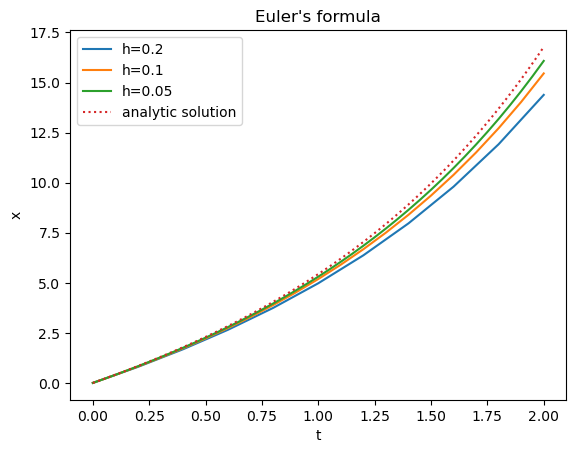

In [4]:
f = lambda x,t: x - 2*t + 4
# Analytic solution
x_t = lambda t: -2 + 2*t + 2*np.exp(t)
# Initial value
x0 = 0
# t_i for different h values
t1 = np.linspace(0,2,11)
t2 = np.linspace(0,2,21)
t3 = np.linspace(0,2,41)
# Solve for each t_i
sol1 = euler(f,x0,t1)
sol2 = euler(f,x0,t2)
sol3 = euler(f,x0,t3)
# Analytic solution for the given initial value
dom = np.linspace(0,2,101)
analytic = x_t(dom)

# Plot
fig = plt.figure()
plt.plot(t1,sol1, label="h=0.2")
plt.plot(t2,sol2, label="h=0.1")
plt.plot(t3,sol3, label="h=0.05")
plt.plot(dom,analytic, linestyle=':', label="analytic solution")
plt.title("Euler's formula")
plt.xlabel("t")
plt.ylabel("x")
plt.legend()
plt.show()

## Midpoint and Runge-Kutta Methods

The **midpoint method** first takes an Euler half step $\hat{x}_i = x_i + \frac{h}{2}f(x_i, t_i)$, evaluates the derivative there, and steps the full $h$ in that direction:

$$x_{i+1} = x_i + h f\!\left(x_i + \tfrac{h}{2}f(x_i, t_i),\; t_i + \tfrac{h}{2}\right).$$

Its local truncation error is $O(h^3)$, so its global error is $O(h^2)$, at the cost of an extra evaluation of $f$ per step.

Both methods belong to the **Runge-Kutta** family. The fourth-order Runge-Kutta method (**RK4**) iterates

$$\begin{aligned}
K_1 &= f(x_i, t_i), \\
K_2 &= f\!\left(x_i + \tfrac{h}{2}K_1,\; t_i + \tfrac{h}{2}\right), \\
K_3 &= f\!\left(x_i + \tfrac{h}{2}K_2,\; t_i + \tfrac{h}{2}\right), \\
K_4 &= f(x_i + hK_3,\; t_{i+1}), \\
x_{i+1} &= x_i + \tfrac{h}{6}(K_1 + 2K_2 + 2K_3 + K_4).
\end{aligned}$$

These generalize quadrature rules: when $x'(t) = f(t)$ has no $x$ dependence, Euler's method is the left-hand rule, the midpoint method is the midpoint rule, and RK4 reduces to Simpson's rule.

### Order of accuracy

A method of order $p$ has relative error $E(h) = Ch^p$, so $\log E(h) = p\log h + \log C$: on a log-log plot against $h$, $E(h)$ is a line of slope $p$.

## Problem 2: Midpoint and RK4

> **Problem 2.** Write functions that implement the midpoint and fourth-order Runge-Kutta methods. Then, consider again the IVP from Problem 1. Use the Euler, Midpoint, and RK4 methods to approximate the value of the solution for step sizes of $h = 0.2$, $0.1$, $0.05$, $0.025$, and $0.0125$. Plot the true solution alongside the approximation obtained from each method when $h = 0.2$. Then, use `plt.loglog` to create a log-log plot of the relative error $|x(2) - x_n|/|x(2)|$ as a function of $h$ for each approximation.

In [5]:
def midpoint(f,x0,t):
    """Numerically approximates the solution to the IVP:
    
    x'(t) = f(x(t),t)
    x(t0) = x0
    
    using the midpoint method.
    Parameters:
        f (function): The right-hand side of the ODE
        x0 ((m,) ndarray): The initial condition
        t ((n,) ndarray): The array of time values
    Returns:
        ((n,m) ndarray): The approximate solution, where x[i] ≈ x(t_i)
    """
    # Initialize array
    solution = [x0]
    # Calculate the stepsize
    h = t[1] - t[0]
    for i in t:
        # Midpoint formula
        x1 = x0 + h*f(x0 + (h/2)*f(x0,i),i + (h/2))
        x0 = x1
        solution.append(x0)
    # Return 1 less so size matches with t
    return solution[:-1]

def rk4(f,x0,t):
    """Numerically approximates the solution to the IVP:
    
    x'(t) = f(x(t),t)
    x(t0) = x0
    
    using a fourth-order Runge-Kutta method.
    Parameters:
        f (function): The right-hand side of the ODE
        x0 ((m,) ndarray): The initial condition
        t ((n,) ndarray): The array of time values
    Returns:
        ((n,m) ndarray): The approximate solution, where x[i] ≈ x(t_i)
    """
    # Initialize array
    solution = [x0]
    # Calculate the stepsize
    h = t[1] - t[0]
    for i in range(len(t)-1):
        # RK4 method
        K1 = f(x0,t[i])
        K2 = f(x0 + (h/2)*K1, t[i] + (h/2))
        K3 = f(x0 + (h/2)*K2, t[i] + (h/2))
        K4 = f(x0 + h*K3, t[i+1])
        x1 = x0 + (h/6)*(K1+2*K2+2*K3+K4)
        x0 = x1
        solution.append(x0)
    # For this one, the size matches exactly
    return solution

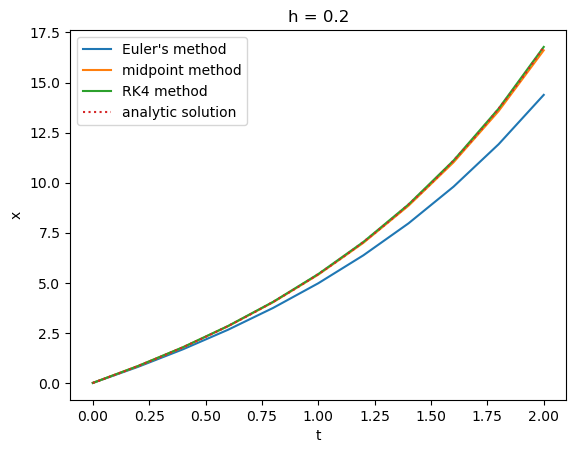

In [6]:
f = lambda x,t: x - 2*t + 4
# Analytic solution
x_t = lambda t: -2 + 2*t + 2*np.exp(t)
# Initial value
x0 = 0
# Stepsize
h = 0.2
t = np.linspace(0,2, int(2/h) + 1)
# Approximate the solution using each method
euler_sol = euler(f, x0, t)
mid_sol = midpoint(f, x0, t)
rk4_sol = rk4(f, x0, t)

# Plot
fig = plt.figure()
plt.plot(t, euler_sol, label="Euler's method")
plt.plot(t, mid_sol, label="midpoint method")
plt.plot(t, rk4_sol, label="RK4 method")
plt.plot(dom,analytic, linestyle=':', label="analytic solution")
plt.title("h = " + str(h))
plt.xlabel("t")
plt.ylabel("x")
plt.legend()
plt.show()

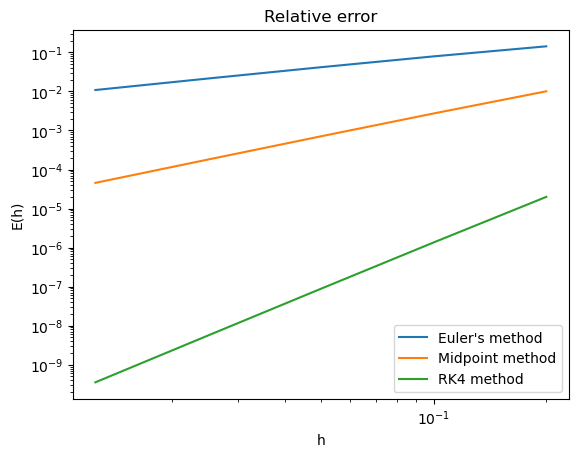

In [7]:
# Store all the h values in an array
h = [0.2*(1/2)**n for n in range(5)]
# Initialize arrays to store error
euler_err = []
midpoint_err = []
rk4_err = []
# Actual value
x_2 = x_t(2)
for _h in h:
    # Domain for each array
    t = np.linspace(0,2, int(2/_h) + 1)
    # Approx. solution for each method
    euler_sol = euler(f, x0, t)
    mid_sol = midpoint(f, x0, t)
    rk4_sol = rk4(f, x0, t)
    # Calculate the error then store the value
    euler_err.append(abs(x_2-euler_sol[-1])/abs(x_2))
    midpoint_err.append(abs(x_2-mid_sol[-1])/abs(x_2))
    rk4_err.append(abs(x_2-rk4_sol[-1])/abs(x_2))

# Plot
fig = plt.figure()
plt.loglog(h,euler_err, label="Euler's method")
plt.loglog(h,midpoint_err, label="Midpoint method")
plt.loglog(h,rk4_err, label="RK4 method")
plt.xlabel('h')
plt.ylabel('E(h)')
plt.title("Relative error")
plt.legend()
plt.show()

The slopes of the log-log lines should be about 1, 2 and 4:

In [8]:
for name, err in [("Euler", euler_err), ("Midpoint", midpoint_err), ("RK4", rk4_err)]:
    slope = np.polyfit(np.log(h), np.log(err), 1)[0]
    print(f"{name:8s} slope = {slope:.3f}")

Euler    slope = 0.932
Midpoint slope = 1.950
RK4      slope = 3.946


Higher-order methods need more evaluations of $f$ per step, but measured by the number of $f$-evaluations needed to reach a given accuracy they are usually much more efficient. For $x'(t) = x(t)\cos(t)$, $t \in [0, 8]$, $x(0) = 1$, RK4 reaches a given relative error at $x(8)$ with far fewer evaluations than Euler or midpoint. As $h$ shrinks, every method eventually stops improving, when floating point round-off overwhelms the truncation error; higher-order methods reach a smaller error before that happens.

## Harmonic Oscillators and Resonance

Harmonic oscillators (a pendulum with small displacement, spring-mass systems, electrical circuits) solve

$$my'' + \gamma y' + ky = f(t), \qquad y(0) = y_0,\; y'(0) = y_0',$$

where $m$ is the mass on the end of a spring, $\gamma$ the damping, $k$ the spring constant and $f(t)$ the external force.

### Simple harmonic oscillators

With no damping ($\gamma = 0$) and no forcing ($f = 0$), $my'' + ky = 0$ has solution $y = c_1\cos(\omega_0 t) + c_2\sin(\omega_0 t)$, where $\omega_0 = \sqrt{k/m}$ is the *natural frequency*. To use a Runge-Kutta method, set $x_1 = y$, $x_2 = y'$, so

$$x' = \begin{bmatrix} x_1 \\ x_2 \end{bmatrix}' = \begin{bmatrix} x_2 \\ -\frac{k}{m}x_1 \end{bmatrix} = f(x(t), t).$$

## Problem 3: A simple harmonic oscillator

> **Problem 3.** Use the RK4 method to solve for the simple harmonic oscillator satisfying:
>
> $$my'' + ky = 0, \quad 0 \le t \le 20, \qquad y(0) = 2,\; y'(0) = -1.$$

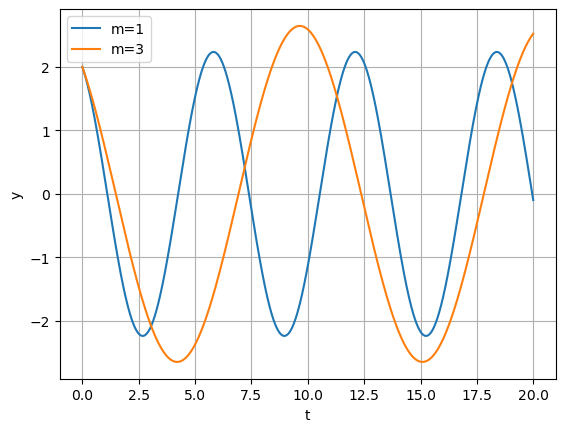

In [9]:
# m=1, k=1
f2 = lambda x,t: np.array([x[1], -x[0]])
# m=3, k=1
f3 = lambda x,t: np.array([x[1], -(1/3)*x[0]])
# Initial value
y0 = [2, -1]
t = np.linspace(0,20,int(20/0.0125) + 1)
# Use RK4 to approximate
sol = np.array(rk4(f2, y0, t))
sol2 = np.array(rk4(f3, y0, t))

# Plot
fig = plt.figure()
plt.plot(t, sol[:,0], label='m=1')
plt.plot(t, sol2[:,0], label='m=3')
plt.grid(True)
plt.xlabel('t')
plt.ylabel('y')
plt.legend()
plt.show()

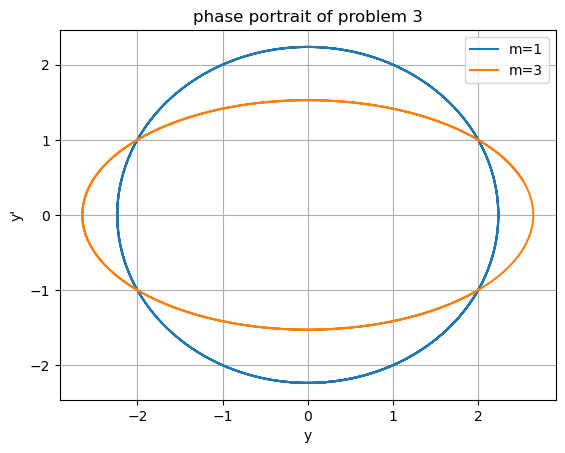

In [10]:
# Phase portrait
fig = plt.figure()
plt.plot(sol[:,0], sol[:,1], label='m=1')
plt.plot(sol2[:,0], sol2[:,1], label='m=3')
plt.xlabel('y')
plt.ylabel('y\'')
plt.legend()
plt.title("phase portrait of problem 3")
plt.grid(True)
plt.show()

### Damped free harmonic oscillators

For $my'' + \gamma y' + ky = 0$, the characteristic roots are

$$r_1, r_2 = \frac{-\gamma \pm \sqrt{\gamma^2 - 4km}}{2m},$$

whose real parts are always negative, so every solution decays as the system loses energy:

1. $\gamma^2 > 4km$ (*overdamped*): $y(t) = c_1e^{r_1t} + c_2e^{r_2t}$, with no oscillation.
2. $\gamma^2 = 4km$ (*critically damped*): $y(t) = c_1e^{-\gamma t/2m} + c_2te^{-\gamma t/2m}$.
3. $\gamma^2 < 4km$: $y(t) = e^{-\gamma t/2m}[c_1\cos(\mu t) + c_2\sin(\mu t)] = Re^{-\gamma t/2m}\sin(\mu t + \delta)$, with $\mu = \sqrt{4km - \gamma^2}/2m$. This system does oscillate.

## Problem 4: A damped free oscillator

> **Problem 4.** Use the RK4 method to solve for the damped free harmonic oscillator satisfying
>
> $$y'' + \gamma y' + y = 0, \quad 0 \le t \le 20, \qquad y(0) = 1,\; y'(0) = -1.$$
>
> For $\gamma = 1/2$, and $\gamma = 1$, simultaneously plot your numerical approximations of $y$.

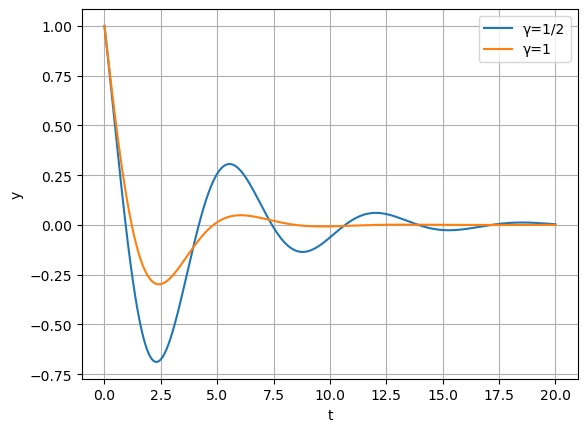

In [11]:
# Gamme=1/2
f2 = lambda x,t: np.array([x[1], -(1/2)*x[1] - x[0]])
# Gamma=1
f3 = lambda x,t: np.array([x[1], -x[1] - x[0]])
# Initial value
y0 = [1, -1]
t = np.linspace(0,20,int(20/0.0125) + 1)
# Use RK4 to approximate
sol = np.array(rk4(f2, y0, t))
sol2 = np.array(rk4(f3, y0, t))

# Plot
fig = plt.figure()
plt.plot(t, sol[:,0], label='γ=1/2')
plt.plot(t, sol2[:,0], label='γ=1')
plt.xlabel('t')
plt.ylabel('y')
plt.grid(True)
plt.legend()
plt.show()

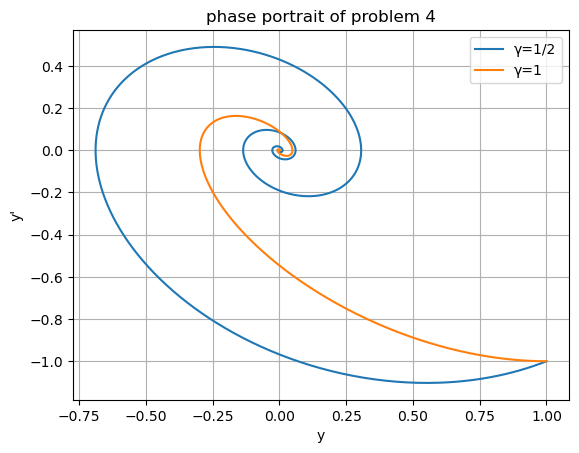

In [12]:
# Phase portrait
fig = plt.figure()
plt.plot(sol[:,0], sol[:,1], label='γ=1/2')
plt.plot(sol2[:,0], sol2[:,1], label='γ=1')
plt.xlabel('y')
plt.ylabel('y\'')
plt.title("phase portrait of problem 4")
plt.grid(True)
plt.legend()
plt.show()

### Forced harmonic oscillators without damping

Consider

$$my''(t) + ky(t) = F(t)$$

with a periodic force $F(t) = F_0\cos(\omega t)$. If $\omega_0 = \sqrt{k/m} \neq \omega$, the general solution is

$$y(t) = c_1\cos(\omega_0t) + c_2\sin(\omega_0t) + \frac{F_0}{m(\omega_0^2 - \omega^2)}\cos(\omega t),$$

and if $\omega_0 = \omega$ it is

$$y(t) = c_1\cos(\omega_0t) + c_2\sin(\omega_0t) + \frac{F_0}{2m\omega_0}t\sin(\omega_0t).$$

When $\omega_0 = \omega$ the solution grows without bound as $t \to \infty$. With damping it stays bounded, but is still large for small $\gamma$ and $\omega$ close to $\omega_0$. This equation holds only for small oscillations, where Hooke's law applies, but the large oscillations it predicts suggest the spring-mass system could fall apart: this mechanical resonance has been known to cause failure of bridges, buildings, and airplanes.

## Problem 5: A damped and forced oscillator

> **Problem 5.** Use the RK4 method to solve for the damped and forced harmonic oscillator satisfying
>
> $$2y'' + \gamma y' + 2y = 2\cos(\omega t), \quad 0 \le t \le 40, \qquad y(0) = 2,\; y'(0) = -1.$$
>
> For the following values of $\gamma$ and $\omega$, plot your numerical approximations of $y(t)$: $(\gamma, \omega) = (0.5, 1.5)$, $(0.1, 1.1)$, and $(0, 1)$.

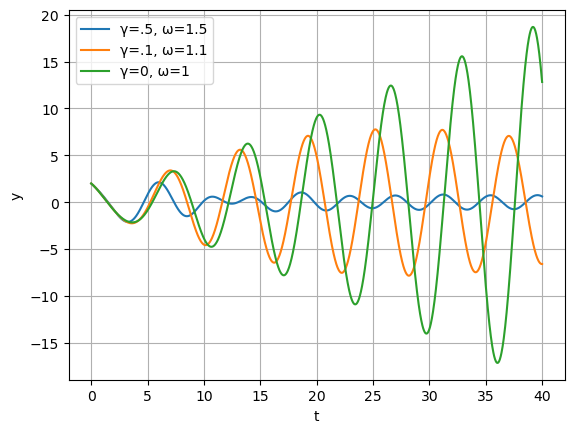

In [13]:
# (γ,ω)=(0.5, 1.5)
f1 = lambda x,t: np.array([x[1], -(1/4)*x[1] - x[0] + np.cos(1.5*t)]) 
# (γ,ω)=(0.1, 1.1)
f2 = lambda x,t: np.array([x[1], -(1/20)*x[1] - x[0] + np.cos(1.1*t)])
# (γ,ω)=(0, 1)
f3 = lambda x,t: np.array([x[1], -x[0] + np.cos(t)])
# Initial value
y0 = [2, -1]
t = np.linspace(0,40,int(20/0.0125) + 1)
# Approximate the solution using RK4
sol = np.array(rk4(f1, y0, t))
sol2 = np.array(rk4(f2, y0, t))
sol3 = np.array(rk4(f3, y0, t))

# Plot
fig = plt.figure()
plt.plot(t, sol[:,0], label='γ=.5, ω=1.5')
plt.plot(t, sol2[:,0], label='γ=.1, ω=1.1')
plt.plot(t, sol3[:,0], label="γ=0, ω=1")
plt.xlabel('t')
plt.ylabel('y')
plt.grid(True)
plt.legend()
plt.show()

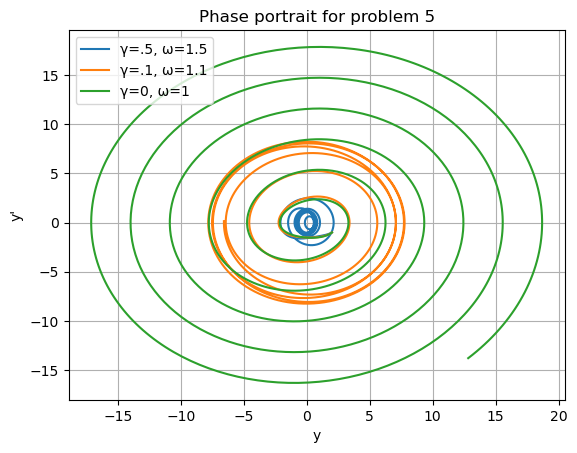

In [14]:
# Plot phase portrait
fig = plt.figure()
plt.plot(sol[:,0], sol[:,1], label='γ=.5, ω=1.5')
plt.plot(sol2[:,0], sol2[:,1], label='γ=.1, ω=1.1')
plt.plot(sol3[:,0], sol3[:,1], label="γ=0, ω=1")
plt.xlabel('y')
plt.ylabel('y\'')
plt.title("Phase portrait for problem 5")
plt.grid(True)
plt.legend()
plt.show()